In [ ]:
%pip install langchain langgraph langchain-google-genai langchain-core -q

In [5]:
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI

api_key = userdata.get("Gemini_API_Key")
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", api_key=api_key)


In [6]:
from langchain_core.prompts import ChatPromptTemplate

GENERATE_QUESTIONS_PROMPT = ChatPromptTemplate.from_template("""
You are an expert technical interviewer. Based on the job role and experience level, generate exactly 5 relevant technical questions.
Job Role: {job_role}
Experience Level: {experience} years
Generate 5 questions that are:
1. Appropriate for the experience level
2. Technical and role-specific
3. Progressive in difficulty
4. Cover different aspects of the role
Return ONLY a JSON array of 5 questions, no explanations.
""")

EVALUATE_ANSWER_PROMPT = ChatPromptTemplate.from_template("""
You are an expert technical interviewer evaluating a candidate's answer.
Job Role: {job_role}
Experience Level: {experience} years
Question: {question}
Candidate's Answer: {answer}
Provide a detailed evaluation including:
1. Technical accuracy (1-10)
2. Completeness of answer (1-10)
3. Clarity of explanation (1-10)
4. Specific feedback and suggestions
5. Overall score (1-10)
Format your response as:
Score: X/10
Technical Accuracy: X/10
Completeness: X/10
Clarity: X/10
Feedback: [Your detailed feedback here]
""")

FINAL_REPORT_PROMPT = ChatPromptTemplate.from_template("""
You are an expert technical interviewer creating a comprehensive interview report.
Job Role: {job_role}
Experience Level: {experience} years
Interview Results:
{interview_results}
Create a professional final report including:
1. Overall assessment
2. Strengths identified
3. Areas for improvement
4. Technical competency score (average of all scores)
5. Recommendation (Pass/Fail/Consider with conditions)
6. Detailed breakdown of each question
Format as a professional report.
""")

In [7]:
from typing import TypedDict

class InterviewState(TypedDict):
    job_role: str
    experience: int
    data: list[dict]
    current_question_idx: int
    interview_complete: bool
    final_report: str

initial_state = {
    "job_role": "",
    "experience": 0,
    "data": [],
    "current_question_idx": 0,
    "interview_complete": False,
    "final_report": "",
}


In [8]:
import json

def get_job_role_and_experience(state):
    state["job_role"] = input("Job role: ")
    state["experience"] = int(input("Years of experience: "))
    return state


def generate_questions(state):
    prompt = GENERATE_QUESTIONS_PROMPT.format_messages(
        job_role=state["job_role"],
        experience=state["experience"],
    )
    response = llm.invoke(prompt)
    questions = json.loads(response.text)
    state["data"] = [
        {"question": question, "answer": "", "feedback": ""}
        for question in questions
    ]
    return state


def ask_question(state):
    number = state["current_question_idx"]
    question = state["data"][number]["question"]
    print("Question", number + 1, ":", question)
    state["data"][number]["answer"] = input("Your answer: ")
    return state


def evaluate_answer(state):
    number = state["current_question_idx"]
    item = state["data"][number]
    prompt = EVALUATE_ANSWER_PROMPT.format_messages(
        job_role=state["job_role"],
        experience=state["experience"],
        question=item["question"],
        answer=item["answer"],
    )
    item["feedback"] = llm.invoke(prompt).text
    print("Feedback:", item["feedback"])
    state["current_question_idx"] += 1
    return state


def should_continue_interview(state):
    if state["current_question_idx"] < len(state["data"]):
        return "continue"
    return "complete"


def generate_final_report(state):
    results = ""
    for item in state["data"]:
        results += "Question: " + item["question"] + "\n"
        results += "Answer: " + item["answer"] + "\n"
        results += "Feedback: " + item["feedback"] + "\n\n"

    prompt = FINAL_REPORT_PROMPT.format_messages(
        job_role=state["job_role"],
        experience=state["experience"],
        interview_results=results,
    )
    state["final_report"] = llm.invoke(prompt).text
    state["interview_complete"] = True
    print(state["final_report"])
    return state


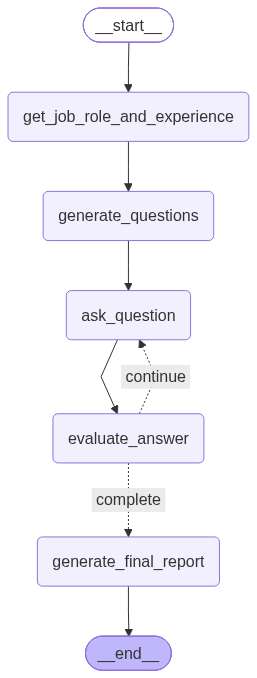

In [9]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

workflow = StateGraph(InterviewState)
workflow.add_node("get_job_role_and_experience", get_job_role_and_experience)
workflow.add_node("generate_questions", generate_questions)
workflow.add_node("ask_question", ask_question)
workflow.add_node("evaluate_answer", evaluate_answer)
workflow.add_node("generate_final_report", generate_final_report)

workflow.add_edge(START, "get_job_role_and_experience")
workflow.add_edge("get_job_role_and_experience", "generate_questions")
workflow.add_edge("generate_questions", "ask_question")
workflow.add_edge("ask_question", "evaluate_answer")
workflow.add_conditional_edges("evaluate_answer", should_continue_interview, {
    "continue": "ask_question",
    "complete": "generate_final_report",
})
workflow.add_edge("generate_final_report", END)

app = workflow.compile()
display(Image(app.get_graph().draw_mermaid_png()))


In [10]:
final_state = app.invoke(initial_state)


Job role: Frontend developer
Years of experience: 2
Question 1 : What is the difference between CSS Flexbox and CSS Grid, and when would you choose one over the other for a component layout?
Your answer: hi
Feedback: Score: 1/10
Technical Accuracy: 1/10
Completeness: 1/10
Clarity: 1/10
Feedback: The candidate's response ("hi") fails to answer the question entirely. For a Frontend Developer position at a 2-year experience level, a candidate is expected to clearly articulate that Flexbox is designed for one-dimensional layouts (either a row or a column), whereas CSS Grid is designed for two-dimensional layouts (rows and columns simultaneously). Furthermore, they should be able to explain use cases, such as using Flexbox for component-level alignments (like navigation bars or button groups) and Grid for overall page layouts or complex two-dimensional card grids. The candidate needs to provide a substantive technical answer.
Question 2 : Can you explain the concept of closures in JavaScrip

KeyboardInterrupt: Interrupted by user